In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn as sk
import sklearn.metrics as skl
 
from sklearn.linear_model import LinearRegression

import seaborn as sns

from sklearn.model_selection import train_test_split
from  sklearn import metrics


from sklearn.metrics import classification_report

from sklearn.metrics import r2_score,accuracy_score

In [2]:
import statsmodels.api as sum
import statsmodels.formula.api as smf

In [3]:
df=pd.read_csv("data-fuel-consumption.csv")
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [4]:
df

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1062,2014,VOLVO,XC60 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1063,2014,VOLVO,XC60 AWD,SUV - SMALL,3.2,6,AS6,X,13.2,9.5,11.5,25,264
1064,2014,VOLVO,XC70 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1065,2014,VOLVO,XC70 AWD,SUV - SMALL,3.2,6,AS6,X,12.9,9.3,11.3,25,260


In [5]:
df.shape

(1067, 13)

In [6]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [7]:
df.columns

Index(['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'ENGINESIZE', 'CYLINDERS',
       'TRANSMISSION', 'FUELTYPE', 'FUELCONSUMPTION_CITY',
       'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB',
       'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS'],
      dtype='str')

In [8]:
statMDL=smf.ols("CO2EMISSIONS~ENGINESIZE+CYLINDERS+FUELCONSUMPTION_CITY+FUELCONSUMPTION_HWY+FUELCONSUMPTION_COMB+FUELCONSUMPTION_COMB_MPG", data=df).fit()
print(statMDL.summary())

                            OLS Regression Results                            
Dep. Variable:           CO2EMISSIONS   R-squared:                       0.889
Model:                            OLS   Adj. R-squared:                  0.889
Method:                 Least Squares   F-statistic:                     1419.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        01:15:17   Log-Likelihood:                -4766.4
No. Observations:                1067   AIC:                             9547.
Df Residuals:                    1060   BIC:                             9582.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

In [9]:
x=df[['ENGINESIZE', 'CYLINDERS','FUELCONSUMPTION_COMB_MPG']]
y=df["CO2EMISSIONS"]

X_train,X_test,y_train,y_test= train_test_split(
    x,
    y,
    test_size=0.25,
    random_state=5
)

In [10]:
linreg= LinearRegression()
linreg.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[11.11, 6.34,-4.73]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB_MPG']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,307.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [11]:
y_predict=linreg.predict(X_test)

In [12]:
print(f"Coefficent : {linreg.coef_}")
print(f"Intercept : {linreg.intercept_}")
print(f"MAE : {metrics.mean_absolute_error(y_test,y_predict)}")
print(f"MSE : {metrics.mean_squared_error(y_test,y_predict)}")

print(f"RMSE : {np.sqrt(metrics.mean_squared_error(y_test,y_predict))}")


Coefficent : [11.11172826  6.34337788 -4.73059216]
Intercept : 307.11680469186086
MAE : 14.528021284008478
MSE : 487.38392410064785
RMSE : 22.076773407829503


In [13]:
accuracy=linreg.score(X_test,y_test)
print(f"AccuracyII : {accuracy*100}%")
print(f"R2_Score : {r2_score(y_test,y_predict)}")

AccuracyII : 88.53480655959554%
R2_Score : 0.8853480655959554


In [14]:
print(f"Train set Accuracy : {r2_score(y_train, linreg.predict(X_train))}")
print(f"R2_Score : {r2_score(y_test,y_predict)}")


Train set Accuracy : 0.8827636444239391
R2_Score : 0.8853480655959554


<Axes: xlabel='CO2EMISSIONS'>

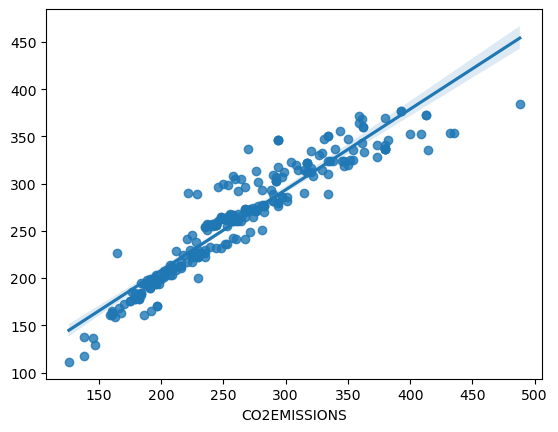

In [15]:
sns.regplot(x=y_test, y=y_predict)

In [16]:
df2=pd.DataFrame({"Actual":y_test, "Predicted":y_predict})


# Actual vs Predicted Plot

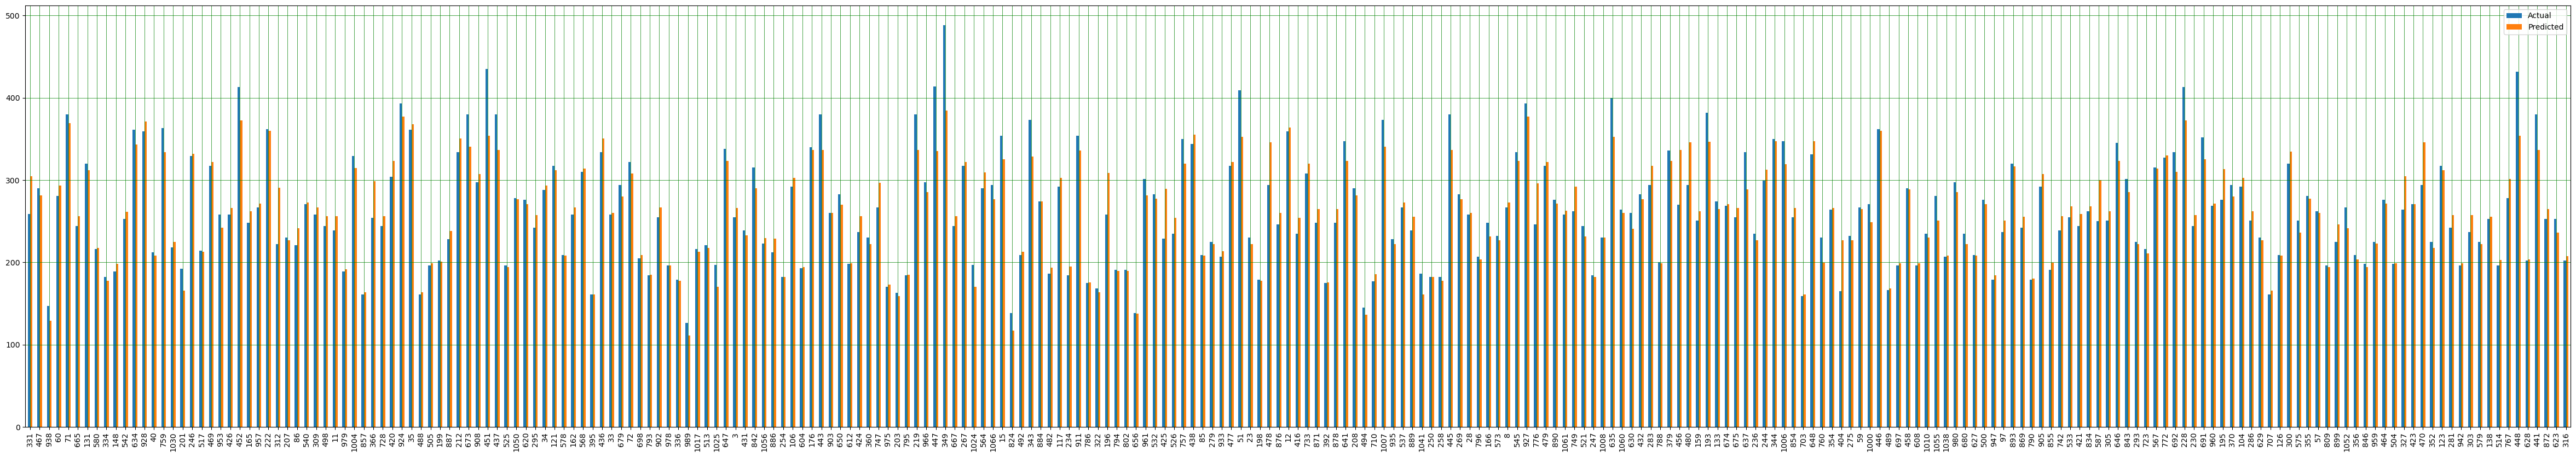

In [17]:
df2.plot(kind="bar", figsize=(60,10))
plt.grid(which="major", linestyle="-", linewidth='0.5', color='green')
plt.grid(which="minor", linestyle=":", linewidth='0.5', color='red')

plt.show()

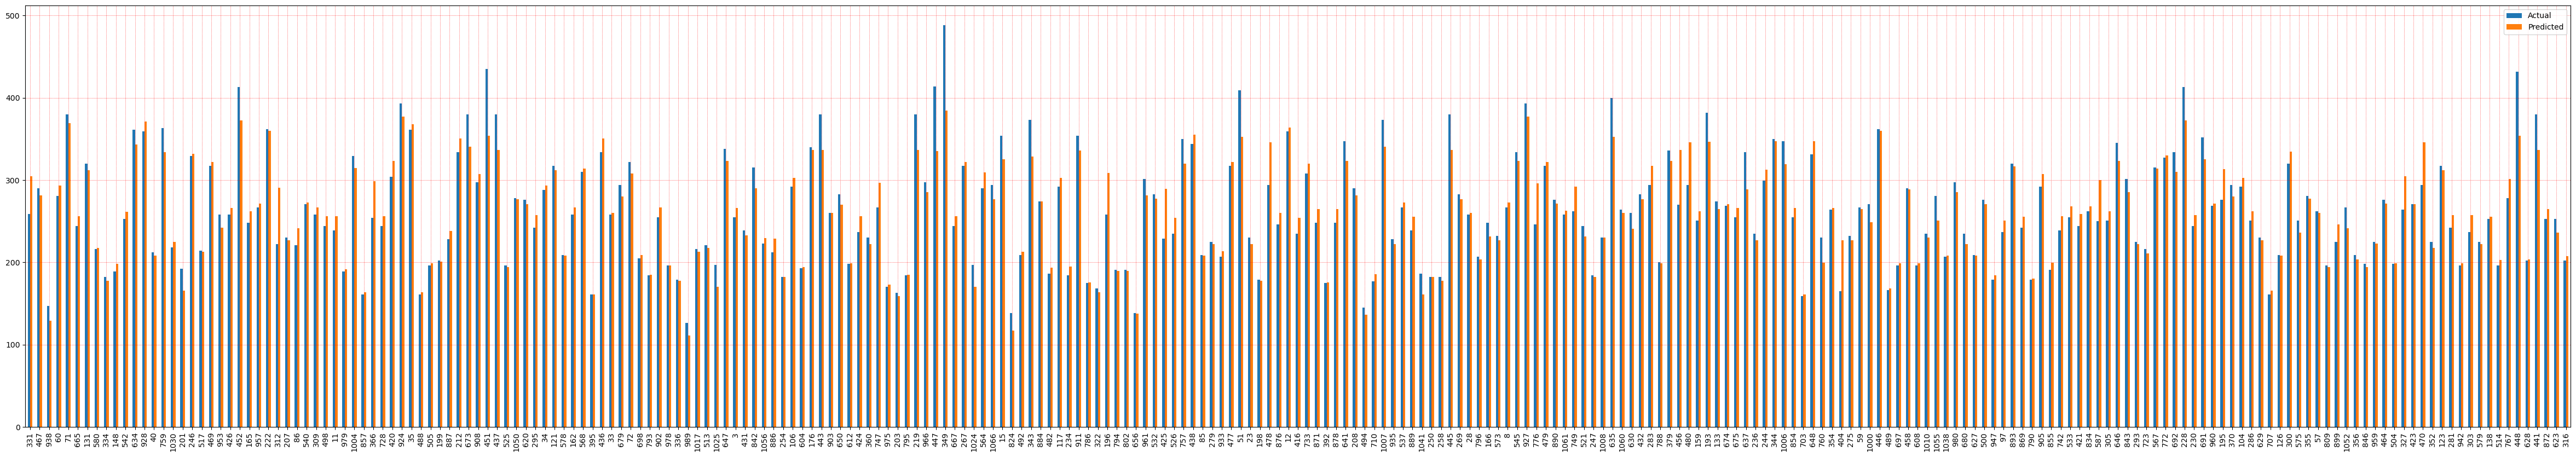

In [18]:
df2.plot(kind="bar", figsize=(60,10))
plt.grid(which="major", linestyle=":", linewidth='0.5', color='red')
plt.grid(which="minor", linestyle="-", linewidth='0.5', color='green')

plt.show()

Locator attempting to generate 1335 ticks ([-0.4, ..., 266.40000000000003]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1335 ticks ([-0.4, ..., 266.40000000000003]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1335 ticks ([-0.4, ..., 266.40000000000003]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1335 ticks ([-0.4, ..., 266.40000000000003]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1335 ticks ([-0.4, ..., 266.40000000000003]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1335 ticks ([-0.4, ..., 266.40000000000003]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1335 ticks ([-0.4, ..., 266.40000000000003]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1335 ticks ([-0.4, ..., 266.40000000000003]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1335 ticks ([-0.4, ..., 266.4000000000000

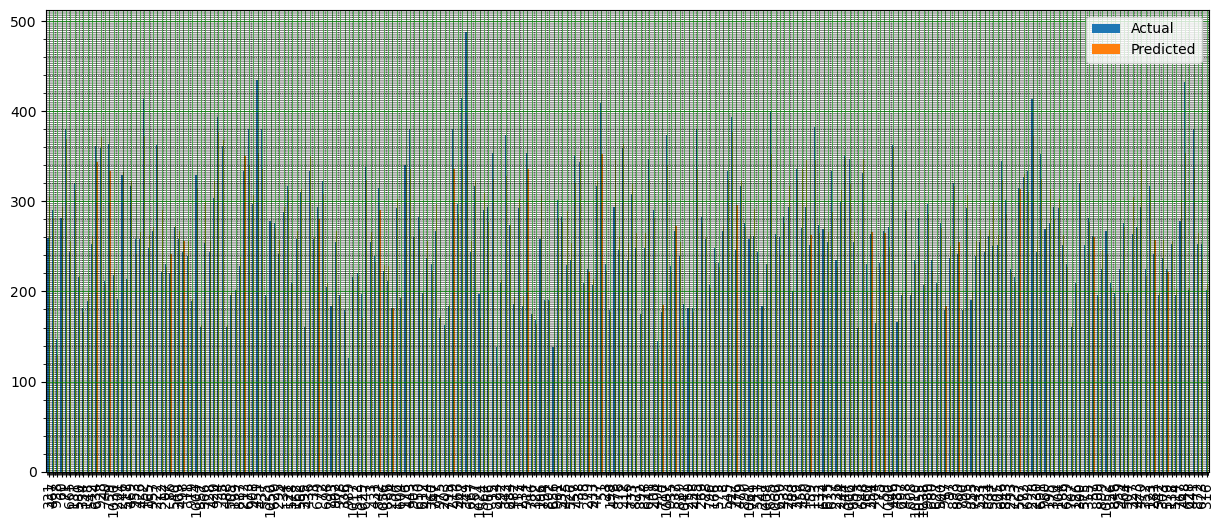

In [19]:
df2 = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_predict
})

df2.plot(kind="bar", figsize=(15, 6))

plt.minorticks_on()

plt.grid(which="major", linestyle="-",
         linewidth=0.5, color="green")

plt.grid(which="minor", linestyle=":",
         linewidth=0.5, color="black")

plt.show()

In [20]:
new_feature_value=[[4,4,6]]

print(f"CO2EMISSIONS: {linreg.predict(new_feature_value)}")

CO2EMISSIONS: [348.55367627]


c:\Users\Lenovo\anaconda3\envs\dm_lab\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [21]:
new_observation = [[4,4, 6]]
linreg.predict(new_observation)

c:\Users\Lenovo\anaconda3\envs\dm_lab\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([348.55367627])

In [22]:
new_observation = pd.DataFrame(
    [[4, 4, 6]],
    columns=['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB_MPG']
)

linreg.predict(new_observation)

array([348.55367627])

In [23]:
from sklearn.preprocessing import PolynomialFeatures

poly=PolynomialFeatures(degree=4)
x_=poly.fit_transform(x)
X_test_=poly.fit_transform(X_test)

In [24]:
polymodel=LinearRegression()
polymodel.fit(x_,y)
Y_poly_predict=polymodel.predict(X_test_)

In [25]:
print("Coefficient : ",polymodel.coef_)
print("Intercept : ", polymodel.intercept_)

Coefficient :  [-1.57951245e-13 -1.37157419e-02 -2.06176656e-02  9.44402948e-02
 -5.90811882e-02 -9.76648646e-02  1.45048288e-01 -1.32661921e-01
  1.88232383e-01  1.19819072e+00 -2.15823486e-01 -2.96914611e-01
  7.21699653e-01 -4.31409655e-01  7.38175983e-01 -1.36456614e-01
 -4.77423047e-01  1.02016898e+00 -3.66881372e-01 -2.30742424e-02
 -2.86780329e-01  1.48796824e-01 -1.55162252e-02  2.90324975e-01
  1.69199480e-01 -3.65214052e-02  3.73912459e-02 -4.56952714e-01
  6.05951721e-02  2.60617949e-04 -3.54053357e-02  1.14194598e-01
 -2.88220454e-02  6.82238089e-03  1.39443664e-05]
Intercept :  68.97267485715213


In [26]:
print(f"AccuracyII : {polymodel.score(X_test_,y_test)*100}%")
print(f"R2_score : {r2_score(y_test,Y_poly_predict)}")

AccuracyII : 92.68375234301791%
R2_score : 0.9268375234301791
